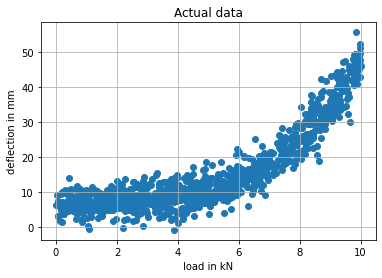

In [111]:
# Import numerical, plotting, neural-network, and preprocessing tools.
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset #for the mini-batches
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

RNG = 10
rng = np.random.default_rng(RNG)

load_kN = rng.uniform(0, 10, 1000)
noise = rng.normal(0, 2.5 + 0.15 * load_kN, 1000)
deflection_mm = 6.0 + 1.45 * load_kN - 0.48 * load_kN**2 + 0.075 * load_kN**3 + noise

plt.scatter(load_kN, deflection_mm)
plt.xlabel('load in kN')
plt.ylabel('deflection in mm')
plt.title('Actual data')
plt.grid()

In [112]:
X_train, X_test, y_train, y_test = train_test_split(
    load_kN.reshape(-1, 1),
    deflection_mm.reshape(-1, 1),
    test_size = 0.2,
    random_state = RNG
)
x_scaler = StandardScaler().fit(X_train)
y_scaler = StandardScaler().fit(y_train)

x_train = torch.tensor(x_scaler.transform(X_train), dtype=torch.float32)
y_train_tensor = torch.tensor(y_scaler.transform(y_train), dtype=torch.float32)

Batch_size = 32
training_loader = DataLoader(
    TensorDataset(x_train, y_train_tensor),
    batch_size = Batch_size,
    shuffle = True,
     generator = torch.Generator().manual_seed(RNG))

print("Number of batches per epoch:", len(training_loader))

Number of batches per epoch: 25


In [113]:
torch.manual_seed(RNG)

model = nn.Sequential(
    nn.Linear(1, 16), nn.Sigmoid(),
    nn.Linear(16, 8), nn.Sigmoid(),
    nn.Linear(8, 1),
)

print(model)

Sequential(
  (0): Linear(in_features=1, out_features=16, bias=True)
  (1): Sigmoid()
  (2): Linear(in_features=16, out_features=8, bias=True)
  (3): Sigmoid()
  (4): Linear(in_features=8, out_features=1, bias=True)
)


0.10467462241649628


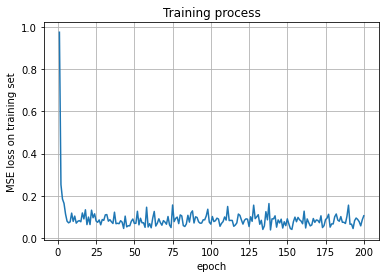

In [114]:
optimizer = torch.optim.Adam(model.parameters(), lr = 0.01)
model.train()
Losses = []
#batch gradient descent
for epoch in range(200):
    for x_batch, y_batch in training_loader:
        optimizer.zero_grad() # resets the gradients
        y_prediction = model(x_batch)
        loss = nn.functional.mse_loss(y_prediction, y_batch) # computes the loss
        loss.backward() #compute the graidients
        optimizer.step() # updates the weights
    Losses.append(loss.item())

plt.plot(np.linspace(1,200,200), Losses)
plt.xlabel('epoch')
plt.ylabel('MSE loss on training set')
plt.grid()
plt.title('Training process')
print(Losses[-1])

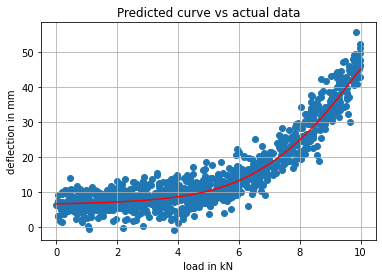

In [115]:
x_plot = np.linspace(0, 10, 200).reshape(-1,1)
x_plot_scaled = torch.tensor(x_scaler.transform(x_plot), dtype=torch.float32)
with torch.no_grad():
    y_plot_normalized = model(x_plot_scaled)

y_plot = y_scaler.inverse_transform(y_plot_normalized)

plt.scatter(load_kN, deflection_mm, label = 'actual data')
plt.plot(x_plot, y_plot, color = 'red', label = 'predicted curve')
plt.xlabel('load in kN')
plt.ylabel('deflection in mm')
plt.title('Predicted curve vs actual data')
plt.grid()

In [116]:
x_test = torch.tensor(x_scaler.transform(X_test), dtype=torch.float32)
y_test_tensor = torch.tensor(y_scaler.transform(y_test), dtype=torch.float32)
with torch.no_grad():
    y_test_prediction = model(x_test)
    test_loss = nn.functional.mse_loss(y_test_prediction, y_test_tensor)
print(test_loss.item())

0.0641947090625763
